# Eye Classification dengan CNN

Model ini mengenali **mata terbuka (`awake`)** dan **mata tertutup (`sleepy`)** dari gambar mata. Kita akan melatih model, melihat hasilnya, lalu mencoba prediksi satu foto.

> `sleepy` adalah nama folder untuk **mata tertutup**, bukan berarti CNN bisa memastikan seseorang mengantuk. Timer dan alarm akan ditambahkan saat integrasi webcam.


## 1. Import Library dan Pengaturan
Dataset disimpan dalam folder `Dataset_or_Sample_Input`, sedangkan notebook dan model hasil training berada dalam folder `Source_Code`.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Lokasi dataset dan pengaturan training
project_directory = Path.cwd().resolve()
if project_directory.name == "Source_Code":
    project_directory = project_directory.parent

data_folder = project_directory / "Dataset_or_Sample_Input"
model_file = project_directory / "Source_Code" / "eye_cnn_best.pth"

image_size = 64
batch_size = 32
num_epochs = 15
learning_rate = 0.001
model_file = "eye_cnn_best.pth"

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dataset:", data_folder)
print("Model:", model_file)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Dataset: C:\Users\Farhan Fitran\Documents\ITS\Semester 5\TEKBER\B_Group01_OpenCV_Final_Submission\Dataset_or_Sample_Input
Model: eye_cnn_best.pth
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Membaca dataset

Struktur folder yang digunakan:

```text
Dataset_or_Sample_Input/
├── train/
│   ├── awake/
│   └── sleepy/
├── val/
│   ├── awake/
│   └── sleepy/
└── test/
    ├── awake/
    └── sleepy/
```

Semua gambar diubah menjadi **grayscale 64×64** dan dinormalisasi. Transformasi yang sama akan digunakan nanti saat prediksi webcam.

In [3]:
image_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data_directory = Path("Dataset_or_Sample_Input")

train_dataset = datasets.ImageFolder(
    data_folder / "train", transform=image_transform
)

validation_dataset = datasets.ImageFolder(
    data_folder / "val", transform=image_transform
)

test_dataset = datasets.ImageFolder(
    data_folder / "test", transform=image_transform
)

class_names = train_dataset.classes
if class_names != ["awake", "sleepy"]:
    raise ValueError(f"Folder kelas harus awake dan sleepy, ditemukan: {class_names}")
if validation_dataset.classes != class_names or test_dataset.classes != class_names:
    raise ValueError("Nama kelas train, val, dan test harus sama.")

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

print("Kelas:", train_dataset.class_to_idx)
print("Jumlah train:", len(train_dataset))
print("Jumlah validation:", len(validation_dataset))
print("Jumlah test:", len(test_dataset))

Kelas: {'awake': 0, 'sleepy': 1}
Jumlah train: 50937
Jumlah validation: 16980
Jumlah test: 16981


## 3. Model CNN

Tiga convolutional layer digunakan untuk mempelajari pola visual mata. Output akhirnya adalah dua kelas: `awake` dan `sleepy`.

In [4]:
class EyeCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)


model = EyeCNN().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

## 4. Training dan validation

Setiap epoch, model belajar dari `train`, kemudian dievaluasi pada `val`. Bobot dengan **validation loss terkecil** disimpan sebagai model terbaik. Dataset `test` belum digunakan pada tahap ini.

In [5]:
train_losses = []
validation_losses = []
train_accuracies = []
validation_accuracies = []
best_validation_loss = float("inf")

for epoch in range(num_epochs):
    # Training
    model.train()
    total_train_loss = 0
    correct_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = model(images)
        loss = loss_function(predictions, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(images)
        correct_train += (predictions.argmax(dim=1) == labels).sum().item()

    train_loss = total_train_loss / len(train_dataset)
    train_accuracy = correct_train / len(train_dataset)

    # Validation (tanpa mengubah bobot model)
    model.eval()
    total_validation_loss = 0
    correct_validation = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images)
            loss = loss_function(predictions, labels)

            total_validation_loss += loss.item() * len(images)
            correct_validation += (predictions.argmax(dim=1) == labels).sum().item()

    validation_loss = total_validation_loss / len(validation_dataset)
    validation_accuracy = correct_validation / len(validation_dataset)

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    train_accuracies.append(train_accuracy)
    validation_accuracies.append(validation_accuracy)

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        torch.save({
            "model_state": model.state_dict(),
            "classes": class_names,
            "image_size": image_size
        }, model_file)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val acc: {validation_accuracy:.2%} | "
        f"Val loss: {validation_loss:.4f}"
    )

print("Model terbaik disimpan:", model_file)

Epoch 1/15 | Train acc: 92.00% | Val acc: 95.35% | Val loss: 0.1310
Epoch 2/15 | Train acc: 96.21% | Val acc: 97.11% | Val loss: 0.0796
Epoch 3/15 | Train acc: 97.17% | Val acc: 97.61% | Val loss: 0.0644
Epoch 4/15 | Train acc: 97.69% | Val acc: 97.89% | Val loss: 0.0586
Epoch 5/15 | Train acc: 97.94% | Val acc: 97.93% | Val loss: 0.0558
Epoch 6/15 | Train acc: 98.13% | Val acc: 98.30% | Val loss: 0.0487
Epoch 7/15 | Train acc: 98.29% | Val acc: 98.26% | Val loss: 0.0477
Epoch 8/15 | Train acc: 98.44% | Val acc: 98.75% | Val loss: 0.0373
Epoch 9/15 | Train acc: 98.57% | Val acc: 98.45% | Val loss: 0.0409
Epoch 10/15 | Train acc: 98.62% | Val acc: 98.66% | Val loss: 0.0384
Epoch 11/15 | Train acc: 98.80% | Val acc: 98.65% | Val loss: 0.0416
Epoch 12/15 | Train acc: 98.76% | Val acc: 98.57% | Val loss: 0.0403
Epoch 13/15 | Train acc: 98.85% | Val acc: 98.72% | Val loss: 0.0379
Epoch 14/15 | Train acc: 98.88% | Val acc: 98.65% | Val loss: 0.0389
Epoch 15/15 | Train acc: 98.90% | Val acc: 

## 5. Grafik training

Lihat apakah nilai loss menurun dan accuracy membaik. Selisih train dan validation yang terlalu besar bisa menjadi tanda overfitting.

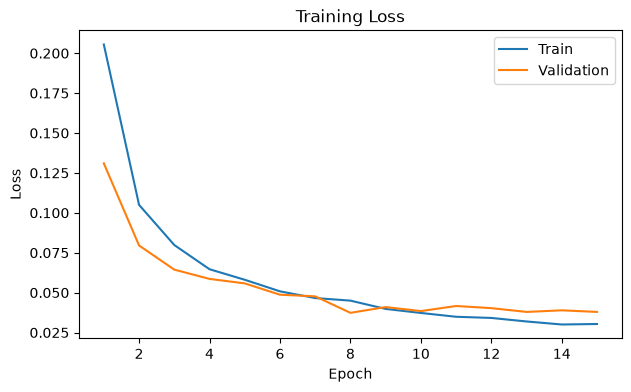

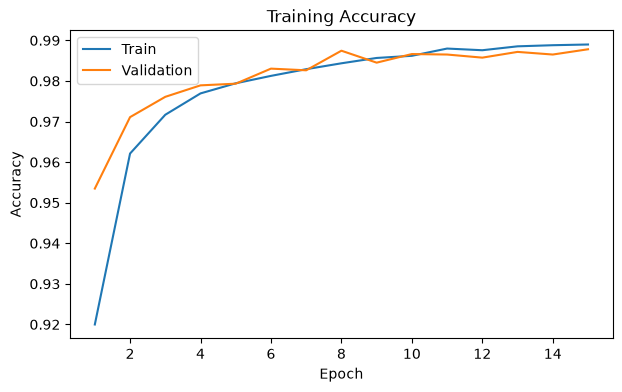

In [6]:
epoch_numbers = range(1, len(train_losses) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_losses, label="Train")
plt.plot(epoch_numbers, validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_accuracies, label="Train")
plt.plot(epoch_numbers, validation_accuracies, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()

## 6. Evaluasi pada data test

Gunakan bobot terbaik dari tahap training. Laporan evaluasi berisi accuracy, precision, recall, F1-score, dan confusion matrix.

              precision    recall  f1-score   support

       awake       0.99      0.99      0.99      8591
      sleepy       0.99      0.98      0.99      8390

    accuracy                           0.99     16981
   macro avg       0.99      0.99      0.99     16981
weighted avg       0.99      0.99      0.99     16981



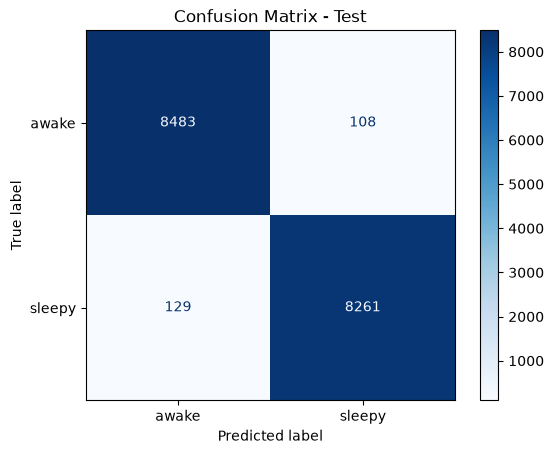

In [12]:
saved_model = torch.load(model_file, map_location=device, weights_only=True)
model.load_state_dict(saved_model["model_state"])
model.eval()

actual_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        predictions = model(images).argmax(dim=1).cpu()

        actual_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.tolist())

print(classification_report(actual_labels, predicted_labels,
                            labels=[0, 1], target_names=class_names,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    actual_labels, predicted_labels,
    labels=[0, 1], display_labels=class_names, cmap="Blues"
)
plt.title("Confusion Matrix - Test")
plt.show()

## 7. Coba prediksi satu foto

Bagian ini memastikan file model yang sudah disimpan bisa dipakai lagi. Ubah `image_path` jika ingin mencoba gambar lain.

Gambar: C:\Users\Farhan Fitran\Documents\ITS\Semester 5\TEKBER\B_Group01_OpenCV_Final_Submission\Dataset_or_Sample_Input\test\awake\s0001_01846_0_0_1_0_0_01.png
Prediksi: awake
Skor prediksi: 99.57%


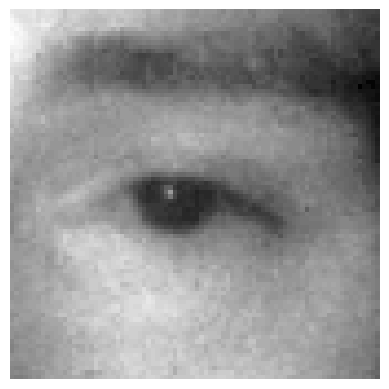

In [ ]:
image_path = Path(test_dataset.samples[0][0])
image = Image.open(image_path).convert("L")
image_tensor = image_transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    scores = model(image_tensor)
    probabilities = torch.softmax(scores, dim=1)[0]

predicted_class = probabilities.argmax().item()
print("Gambar:", image_path)
print("Prediksi:", class_names[predicted_class])
print(f"Skor prediksi: {probabilities[predicted_class].item():.2%}")

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()


### Selanjutnya: Integrasi Webcam Real-Time

Model CNN yang telah dilatih dan disimpan sebagai `eye_cnn_best.pth` digunakan pada aplikasi web berbasis Gradio melalui file `main.py`.

Aplikasi menggunakan webcam laptop sebagai input video secara real-time. Gradio mengambil frame dari webcam melalui browser, kemudian MediaPipe Face Mesh mendeteksi lokasi mata pada wajah pengguna.

Area mata dipotong dan melalui preprocessing yang sama seperti saat training, yaitu konversi grayscale, resizing 64×64, dan normalisasi.

Selanjutnya, CNN mengklasifikasikan kondisi mata menjadi `awake` (terbuka) atau `sleepy` (tertutup). Hasil prediksi dihaluskan menggunakan smoothing untuk mengurangi perubahan status yang tidak stabil.

Ketika mata terdeteksi tertutup secara berkelanjutan selama minimal 2 detik, sistem menampilkan peringatan dan memutar custom alarm. Audio akan berulang sampai sistem kembali mendeteksi mata terbuka.

**Alur Sistem:**

Webcam Browser → MediaPipe Face Mesh → Eye Cropping → Image Preprocessing → CNN Classification → Prediction Smoothing → Eye Closure Timer → Visual Warning & Custom Alarm

**Catatan Pengujian:**

- MRL Eye Dataset menggunakan citra mata inframerah, sedangkan webcam laptop umumnya menghasilkan gambar RGB. Perbedaan karakteristik gambar dapat memengaruhi performa model.
- Akurasi pada dataset test belum tentu menggambarkan performa sistem saat digunakan melalui webcam.
- Pembagian dataset perlu menghindari kebocoran data antar subjek atau sesi pengambilan gambar.
- Label `sleepy` pada dataset digunakan untuk merepresentasikan mata tertutup, bukan diagnosis kondisi kantuk.
- Sistem menggunakan durasi penutupan mata sebagai salah satu indikator kemungkinan kantuk, bukan untuk memastikan seseorang sedang mengantuk.
